# 02 - Feature Engineering, Model Training & Experiment Tracking
Three model families are tuned with 5-fold stratified CV and every run is logged to MLflow.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: D:\BITS\Semester-3\MLOps\MLOPS_Webinar1\heart-disease-mlops


## 1. Data split & preprocessing pipeline

In [2]:
from src.data.clean_data import load_clean_data
from src.features.prepare_data import split_train_test, build_preprocessor
data = load_clean_data()
X_train, X_test, y_train, y_test = split_train_test(data)
print(X_train.shape, X_test.shape, 'positive rate train/test:', round(y_train.mean(),3), round(y_test.mean(),3))
pre = build_preprocessor().fit(X_train)
pre

(242, 13) (61, 13) positive rate train/test: 0.459 0.459


Pipeline(steps=[('engineer', ClinicalFeatureEngineer()),
                ('columns',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak', 'ca',
                                                   'hr_pct_of_max']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='if_binary',
                                                                                 handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'thal'])],
                                   verbose_feature_names_out=False))])

In [3]:
list(pre.named_steps['columns'].get_feature_names_out())

['age',
 'trestbps',
 'chol',
 'thalach',
 'oldpeak',
 'ca',
 'hr_pct_of_max',
 'sex_1.0',
 'cp_1.0',
 'cp_2.0',
 'cp_3.0',
 'cp_4.0',
 'fbs_1.0',
 'restecg_0.0',
 'restecg_1.0',
 'restecg_2.0',
 'exang_1.0',
 'slope_1.0',
 'slope_2.0',
 'slope_3.0',
 'thal_3.0',
 'thal_6.0',
 'thal_7.0']

## 2. Candidate models and tuning grids
Each candidate is a single `Pipeline(preprocess -> model)` so the exact same transformations are used in CV, on the hold-out set and in production.

In [4]:
from src.models.model_pipelines import get_model_specs
for name, (pipe, grid) in get_model_specs().items():
    n = 1
    for v in grid.values(): n *= len(v)
    print(f'{name:20s} {n:3d} candidates  {grid}')

logistic_regression   10 candidates  {'model__C': [0.01, 0.1, 0.5, 1.0, 5.0], 'model__class_weight': [None, 'balanced']}
random_forest         12 candidates  {'model__n_estimators': [200, 500], 'model__max_depth': [None, 4, 8], 'model__min_samples_leaf': [1, 4], 'model__max_features': ['sqrt']}
xgboost                8 candidates  {'model__n_estimators': [100, 300], 'model__max_depth': [2, 3], 'model__learning_rate': [0.03, 0.1], 'model__subsample': [0.8], 'model__colsample_bytree': [0.8]}


## 3. Train -> evaluate -> track -> select -> register -> package
`run_training()` performs GridSearchCV (refit on ROC-AUC, also scoring accuracy/precision/recall/F1), evaluates on the hold-out set, logs **one parent run per model family + one nested run per grid candidate** to MLflow (params, metrics, plots, CV table, model with signature), selects the champion by mean CV ROC-AUC, registers it as `HeartDiseaseRiskChampion` with alias `champion`, and saves deployable artifacts.

In [5]:
import logging; logging.basicConfig(level=logging.WARNING)
from src.models.train import run_training
outcome = run_training()
print('Champion:', outcome['champion'])
outcome['comparison'].drop(columns=['best_params']).round(3).T

2026/10/13 22:35:47 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/13 22:35:59 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/13 22:36:09 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Registered model 'HeartDiseaseRiskChampion' already exists. Creating a new version of this model...
Created version '3' of model 'HeartDiseaseRiskChampion'.
2026/10/13 22:36:16 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Champion: logistic_regression


,logistic_regression,random_forest,xgboost
cv_accuracy_mean,0.855,0.818,0.826
cv_accuracy_std,0.024,0.016,0.022
cv_precision_mean,0.875,0.839,0.838
cv_precision_std,0.072,0.067,0.058
cv_recall_mean,0.810,0.764,0.783
cv_recall_std,0.062,0.098,0.094
cv_f1_mean,0.837,0.792,0.803
cv_f1_std,0.024,0.030,0.035
cv_roc_auc_mean,0.909,0.898,0.894
cv_roc_auc_std,0.018,0.028,0.024


In [6]:
outcome['comparison'][['best_params']]

,best_params
logistic_regression,"{""C"": 0.5, ""class_weight"": ""balanced""}"
random_forest,"{""max_depth"": null, ""max_features"": ""sqrt"", ""m..."
xgboost,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0..."


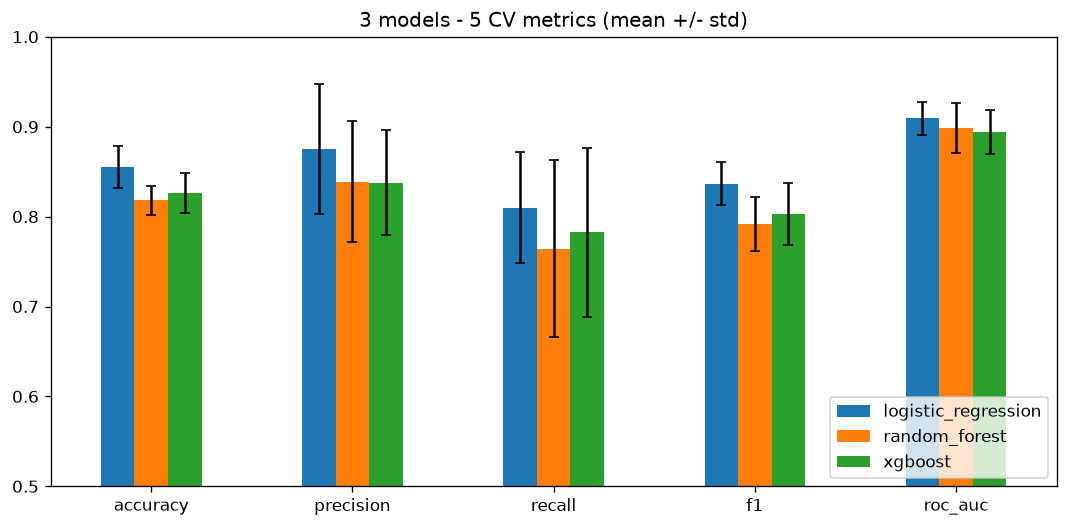

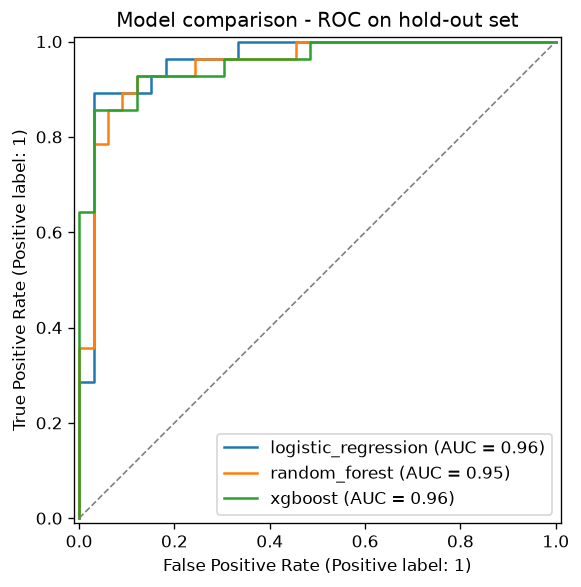

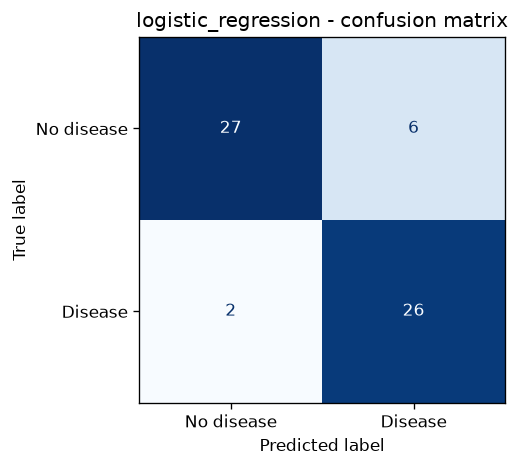

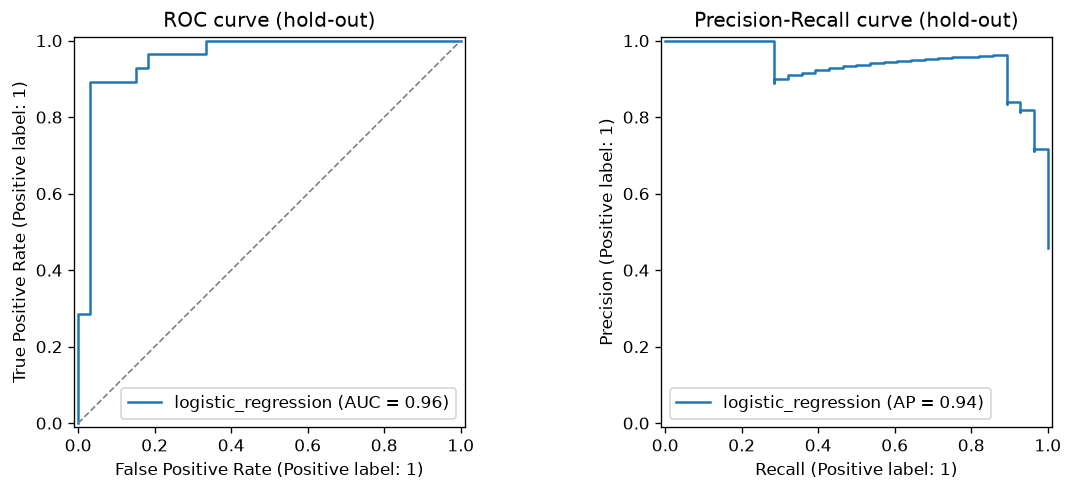

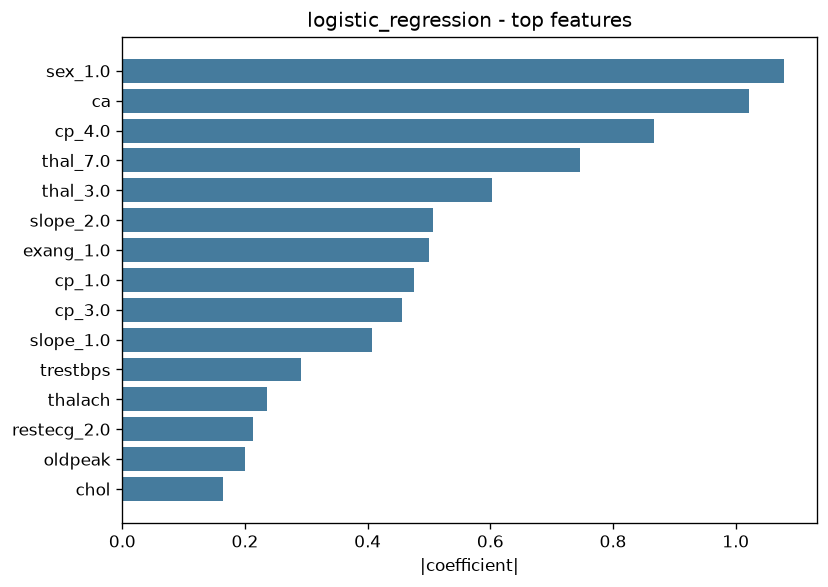

In [7]:
from pathlib import Path
for f in ['comparison_cv_metrics.png', 'comparison_roc.png', f"{outcome['champion']}_confusion_matrix.png", f"{outcome['champion']}_roc_pr.png", f"{outcome['champion']}_feature_importance.png"]:
    display(Image(filename=str(Path('reports/figures/models')/f)))

## 4. MLflow experiment summary
Start the UI with `mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000`.

In [8]:
import mlflow
from src.config import MLFLOW_TRACKING_URI, EXPERIMENT_NAME
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME], filter_string="tags.stage = 'candidate'")
runs[['tags.mlflow.runName','metrics.cv_roc_auc_mean','metrics.test_roc_auc','metrics.test_recall','start_time']].sort_values('start_time', ascending=False).head(6)

,tags.mlflow.runName,metrics.cv_roc_auc_mean,metrics.test_roc_auc,metrics.test_recall,start_time
0,xgboost,0.893895,0.956710,0.928571,2026-10-13 17:06:09.167000+00:00
1,random_forest,0.898485,0.950216,0.928571,2026-10-13 17:05:58.912000+00:00
2,logistic_regression,0.909246,0.957792,0.928571,2026-10-13 17:05:47.219000+00:00
3,xgboost,0.893895,0.956710,0.928571,2026-10-13 17:03:19.876000+00:00
4,random_forest,0.898485,0.950216,0.928571,2026-10-13 17:03:09.593000+00:00
5,logistic_regression,0.909246,0.957792,0.928571,2026-10-13 17:02:59.854000+00:00


In [9]:
from mlflow import MlflowClient
c = MlflowClient()
champ = c.get_model_version_by_alias('HeartDiseaseRiskChampion', 'champion')
print(f"@champion -> version {champ.version} (run {champ.run_id}), tags={champ.tags}")
pd.DataFrame([(v.version, v.tags.get('model_family'), v.tags.get('cv_roc_auc'), v.creation_timestamp)
              for v in c.search_model_versions("name='HeartDiseaseRiskChampion'")],
             columns=['version', 'family', 'cv_roc_auc', 'created_ms'])

@champion -> version 3 (run 33ad8ba71a0940a1a6b31d2f5d93dd97), tags={'model_family': 'logistic_regression', 'cv_roc_auc': '0.9092'}


,version,family,cv_roc_auc,created_ms
0,3,logistic_regression,0.9092,1791911175898
1,2,logistic_regression,0.9092,1791911009848
2,1,logistic_regression,0.9092,1791908771138


## 5. Model selection rationale
* **Selection metric = mean 5-fold CV ROC-AUC** on the training split: threshold-free and much less noisy than the 61-row hold-out set. Ties are broken by hold-out recall (a missed sick patient is the costlier error).
* Logistic regression wins on CV ROC-AUC and CV F1 with the lowest variance; tree ensembles score slightly higher on the small hold-out set but lower in CV - a sign of hold-out noise rather than real superiority.
* LR is also interpretable (coefficients) and tiny/fast to serve.